1. PAINS (Pan-Assay INterference compoundS)

The problem. In HTS, a “hit” is a compound that appears to affect your target. Some compounds appear to work on everything you test them against. That is rarely a sign of a miracle drug. These compounds are usually tricking the assay, so they are false positives.

How they trick the assay. Examples include:

- Sticking non-specifically to proteins
- Being coloured or fluorescent, which disturbs a readout based on light
- Reacting with assay components
- Clumping into aggregates

Researchers (Baell & Holloway, 2010, [J. Med. Chem.](https://doi.org/10.1021/jm901137j)) looked at compounds that kept showing up as hits across many different screens. They then identified the common substructures behind this behaviour and published them as a filter list. Spotting those substructures lets you drop likely false positives before wasting months chasing them.

2. Unwanted substructures (Brenk filters)

Why they matter? A chemical group can be a problem for several reasons:

- Toxic: It can damage DNA or harm organs.
- Reactive: It reacts with random molecules in the body instead of staying inert and doing one job.
- Poor pharmacokinetics: The body absorbs, distributes or clears it badly, so it may never - reach its target or may leave too fast.
- Assay interference: It messes with the lab test and gives misleading results.


| Group | Problem 
| -------- | -------- 
| Nitro groups (–NO₂)  | Mutagenic, meaning they can damage DNA  
| Sulfates and phosphates  | Very charged and water-loving, so they struggle to cross cell membranes and are cleared quickly
|      2-Halopyridines and thiols   | Reactive, so they stick to proteins non-selectively	


The dataset PAINS (is it a likely false-positive "frequent hitter"?)
   → Ro5 (is it drug-like in size and properties?)
   → PAINS (is it a likely false-positive "frequent hitter"?)
   → Brenk (does it contain toxic, reactive or problematic groups?)
   → Cleaner, more promising set of compounds

In [1]:
from pathlib import Path

import pandas as pd
from tqdm.auto import tqdm
from rdkit import Chem
from rdkit.Chem import PandasTools
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams

In [10]:
from pathlib import Path

vegfr2_data = pd.read_csv(Path("data") / "VEGFR-2_Ro5_fulfilled.csv")
vegfr2_data.head()

,Unnamed: 0,molecule_chembl_id,IC50,IC50_units,smiles,pIC50,Molecular Weight,LogP,H-Bond Donors,H-Bond Acceptors,Ro5 Fulfilled
0,0,CHEMBL5189340,0.023,nM,CN(C)c1ccc(/C=N/NC(=O)Cn2nc(Cc3ccc(Cl)cc3)c3cc...,10.638272,473.964,3.85700,1,5,True
1,1,CHEMBL429743,0.030,nM,COc1cc2nccc(Oc3ccc4c(C(=O)Nc5ccc(Cl)cc5)cccc4c...,10.522879,484.939,7.10320,1,5,True
2,4,CHEMBL5186748,0.120,nM,CNC(=O)c1cc(Oc2ccc(NC(=O)c3nn(-c4ccc(Cl)cc4)cc...,9.920819,489.919,3.99352,2,6,True
3,5,CHEMBL3586072,0.140,nM,CNC(=O)c1ccc(-c2ccc(NC(=O)Nc3cc(Br)cc(C(F)(F)F...,9.853872,493.283,5.53350,3,3,True
4,7,CHEMBL3586071,0.150,nM,CNC(=O)c1cc(-c2ccc(NC(=O)Nc3ccc(Cl)c(C(F)(F)F)...,9.823909,448.832,5.42440,3,3,True


In [11]:
vegfr2_data = vegfr2_data.drop(columns=["Molecular Weight", "LogP", "H-Bond Donors", "H-Bond Acceptors"])
vegfr2_data.head()

,Unnamed: 0,molecule_chembl_id,IC50,IC50_units,smiles,pIC50,Ro5 Fulfilled
0,0,CHEMBL5189340,0.023,nM,CN(C)c1ccc(/C=N/NC(=O)Cn2nc(Cc3ccc(Cl)cc3)c3cc...,10.638272,True
1,1,CHEMBL429743,0.030,nM,COc1cc2nccc(Oc3ccc4c(C(=O)Nc5ccc(Cl)cc5)cccc4c...,10.522879,True
2,4,CHEMBL5186748,0.120,nM,CNC(=O)c1cc(Oc2ccc(NC(=O)c3nn(-c4ccc(Cl)cc4)cc...,9.920819,True
3,5,CHEMBL3586072,0.140,nM,CNC(=O)c1ccc(-c2ccc(NC(=O)Nc3cc(Br)cc(C(F)(F)F...,9.853872,True
4,7,CHEMBL3586071,0.150,nM,CNC(=O)c1cc(-c2ccc(NC(=O)Nc3ccc(Cl)c(C(F)(F)F)...,9.823909,True


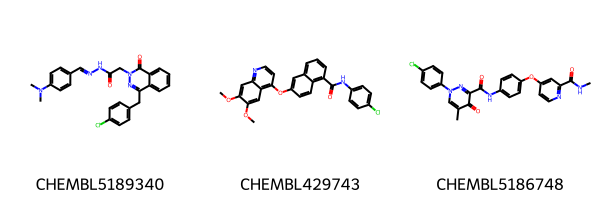

In [12]:
# Add molecule column
PandasTools.AddMoleculeColumnToFrame(vegfr2_data, smilesCol="smiles")
# Draw first 3 molecules
Chem.Draw.MolsToGridImage(
    list(vegfr2_data.head(3).ROMol),
    legends=list(vegfr2_data.head(3).molecule_chembl_id),
)

The following is a standard filteration approach from RDKit [documentation](https://rdkit.org/docs/source/rdkit.Chem.rdfiltercatalog.html) 

In [13]:
params = FilterCatalogParams()
params.AddCatalog(FilterCatalogParams.FilterCatalogs.PAINS)
catalog = FilterCatalog(params)

In [14]:
# search for PAINS
matches = []
clean = []
for index, row in tqdm(vegfr2_data.iterrows(), total=vegfr2_data.shape[0]):
    molecule = Chem.MolFromSmiles(row.smiles)
    entry = catalog.GetFirstMatch(molecule) 
    if entry is not None:
        # store PAINS information
        matches.append(
            {
                "chembl_id": row.molecule_chembl_id,
                "rdkit_molecule": molecule,
                "pains": entry.GetDescription().capitalize(),
            }
        )
    else:
        clean.append(index)

matches = pd.DataFrame(matches)
vegfr2_data = vegfr2_data.loc[clean]  # keep molecules without PAINS

  0%|          | 0/7261 [00:00<?, ?it/s]

In [15]:
print(f"Number of compounds with PAINS: {len(matches)}")
print(f"Number of compounds without PAINS: {len(vegfr2_data)}")

Number of compounds with PAINS: 417
Number of compounds without PAINS: 6844


wanna take a look at the PAINS found?

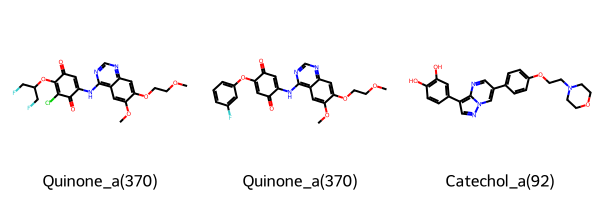

In [16]:
Chem.Draw.MolsToGridImage(
    list(matches.head(3).rdkit_molecule),
    legends=list(matches.head(3)["pains"]),
)

Now we use the [Brenk filters](https://chemistry-europe.onlinelibrary.wiley.com/doi/full/10.1002/cmdc.200700139) to find chemical groups that cause trouble. The dataset can be downloaded either using the original article or through the data folder in this project.

In [ ]:
substructures = pd.read_csv(Path("data") / "unwanted_substructures.csv", sep="\s+")
substructures["rdkit_molecule"] = substructures.smarts.apply(Chem.MolFromSmarts) # convert SMARTS to RDKit molecule

<>:1: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:1: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\Fyn14\AppData\Local\Temp\ipykernel_53220\2388943938.py:1: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  substructures = pd.read_csv(Path("data") / "unwanted_substructures.csv", sep="\s+")


In [22]:
# search for unwanted substructure
matches = []
clean = []
for index, row in tqdm(vegfr2_data.iterrows(), total=vegfr2_data.shape[0]):
    molecule = Chem.MolFromSmiles(row.smiles)
    match = False
    for _, substructure in substructures.iterrows():
        if molecule.HasSubstructMatch(substructure.rdkit_molecule):
            matches.append(
                {
                    "chembl_id": row.molecule_chembl_id,
                    "rdkit_molecule": molecule,
                    "substructure": substructure.rdkit_molecule,
                    "substructure_name": substructure["name"],
                }
            )
            match = True
    if not match:
        clean.append(index)

matches = pd.DataFrame(matches)
vegfr2_data = vegfr2_data.loc[clean]

  0%|          | 0/6844 [00:00<?, ?it/s]

In [23]:
# NBVAL_CHECK_OUTPUT
print(f"Number of found unwanted substructure: {len(matches)}")
print(f"Number of compounds without unwanted substructure: {len(vegfr2_data)}")

Number of found unwanted substructure: 2922
Number of compounds without unwanted substructure: 4923


In [24]:
# NBVAL_CHECK_OUTPUT
groups = matches.groupby("substructure_name")
group_frequencies = groups.size()
group_frequencies.sort_values(ascending=False, inplace=True)
group_frequencies.head(10)

C:\Users\Fyn14\AppData\Local\Temp\ipykernel_53220\3347342451.py:4: Pandas4Warning: The inplace keyword in Series.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  group_frequencies.sort_values(ascending=False, inplace=True)


substructure_name
Aliphatic-long-chain           613
Michael-acceptor               602
Oxygen-nitrogen-single-bond    368
triple-bond                    263
imine                          191
stilbene                       134
halogenated-ring               103
hydroxamic-acid                 99
Thiocarbonyl-group              89
nitro-group                     58
dtype: int64